In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from plot_utils import grid_plot

import numpy as np

In [17]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]


array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object)

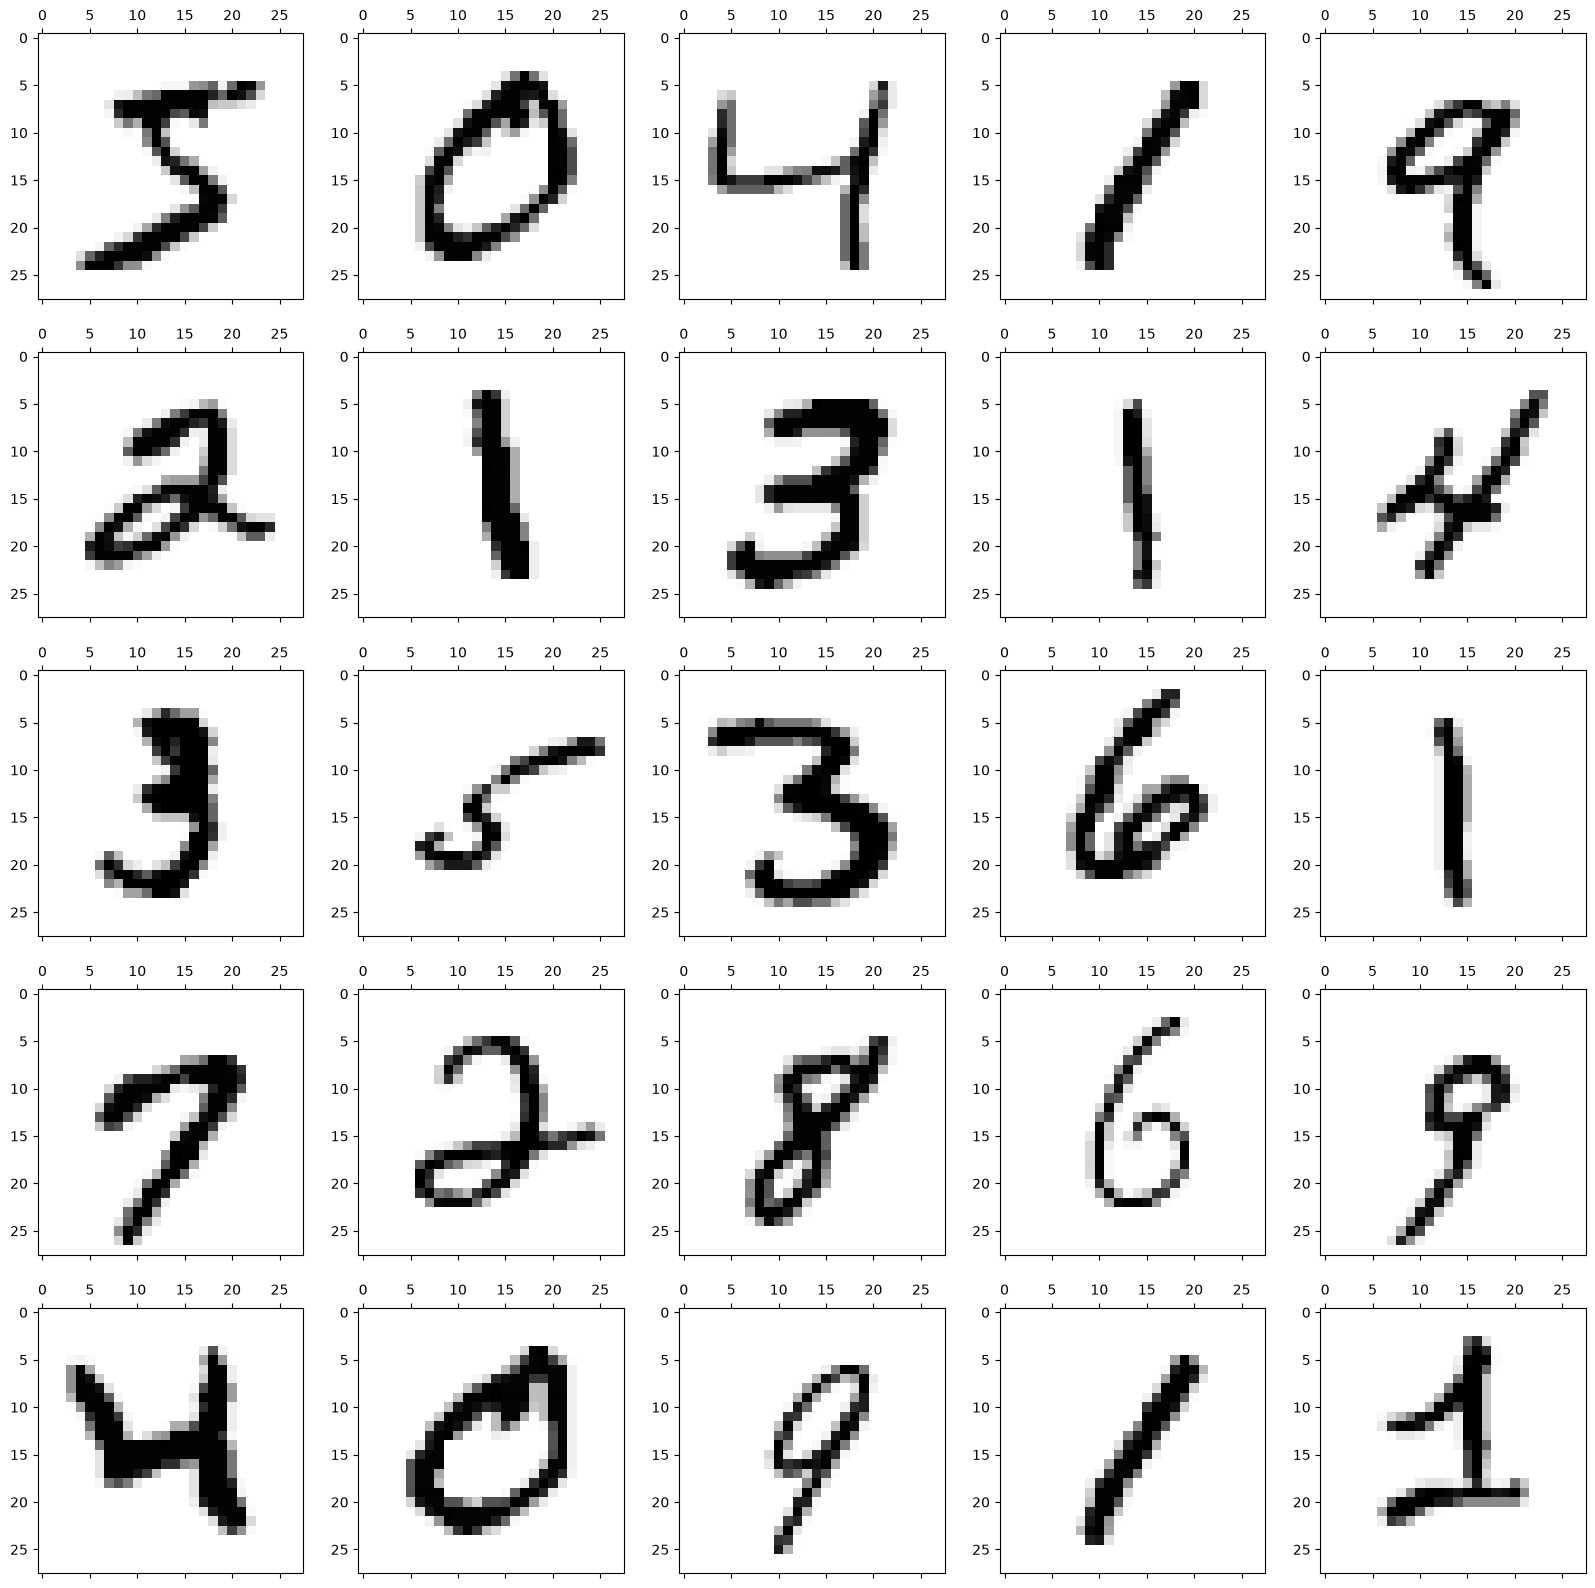

In [18]:
def plot_pc(ax, num, index):
    num_grid = num.reshape(28, -1)

    ax.matshow(num_grid, cmap='Greys')

grid_plot(X_train[0:5*5], 5, 5, plot_pc)

In [19]:

from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(random_state=504, max_depth=12)

tree_clf.fit(X_train, y_train)

tree_clf.score(X_train, y_train), tree_clf.score(X_test, y_test)

(0.9491166666666667, 0.8772)

In [20]:
from sklearn.ensemble import RandomForestClassifier

rcf = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=504, n_jobs=16)
rcf.fit(X_train, y_train)
rcf.score( X_train, y_train), rcf.score(X_test, y_test)

(0.9868666666666667, 0.9605)

In [21]:
importances = zip(range(len(X_train[0])), tree_clf.feature_importances_) #pairs up feature names with performance score
sorted(importances, key=lambda p: -p[1])[:10]

[(489, np.float64(0.058891630842946394)),
 (435, np.float64(0.052621691934119946)),
 (568, np.float64(0.04857364075702864)),
 (350, np.float64(0.048218895224815546)),
 (430, np.float64(0.04211992268966488)),
 (211, np.float64(0.03453404232703753)),
 (346, np.float64(0.029343336285538656)),
 (234, np.float64(0.025237089594893975)),
 (405, np.float64(0.02517767553728819)),
 (156, np.float64(0.021759994976723977))]

In [22]:
from sklearn.ensemble import RandomForestClassifier

rcf = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=504, n_jobs=16)
rcf.fit(X_train, y_train)
rcf.score( X_train, y_train), rcf.score(X_test, y_test)

(0.9868666666666667, 0.9605)

In [23]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=16)
knn.fit(X_train, y_train)
knn.score( X_train, y_train), knn.score(X_test, y_test)

(0.9819166666666667, 0.9688)

In [24]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=504, n_jobs=16)

lr.fit(X_train, y_train)

lr.score(X_train, y_train), lr.score(X_test, y_test)

c:\Users\oih\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=16', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\oih\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


(0.9339166666666666, 0.9255)

In [25]:
from sklearn.linear_model import SGDClassifier

lr = SGDClassifier(random_state=504, loss='log_loss', learning_rate='invscaling', n_jobs=16)

lr.fit(X_train, y_train)

lr.score(X_train, y_train), lr.score(X_test, y_test)

(0.8740666666666667, 0.8645)